# 08 — Fusion Layer: combining Isolation Forest, Autoencoder, and Random Forest

Final component of the ML ensemble layer. Combines the three trained detection models into a
single fused ensemble score:
- `models/random_forest.pkl` — 80-feature set, full population (`data/features/cicids2017_features_*.parquet`).
  Near-perfect in-dataset (val AUC-ROC 0.9998) but structurally blind to zero-day categories
  (LOAO Bot recall 0.0, PortScan 0.002) — supervised, can't recognize a class it never saw.
- `models/isolation_forest_behavioral_v2.pkl` — 92-feature behavioral set (Option A, adopted),
  on the row-hash-join-validated population (~23.6% smaller BENIGN than RF's).
- `models/autoencoder_behavioral_v2.pt` — same behavioral population. LOAO: DDoS recall 0.971,
  PortScan recall 0.778 — genuine zero-day generalization RF cannot achieve by design. Both
  IF-v2 and AE-v2 remain near-zero on Bot/Patator/Web-Attack-Brute-Force regardless of feature
  set — fusion is not expected to fix this.

**Does not retrain any of the three already-saved val-set models** — this notebook only
combines their existing outputs for the main val-set fusion comparison. The LOAO section later
in this notebook does retrain fresh *fold-specific* models (a separate, necessary thing —
zero-day evaluation is impossible without a model that never saw the held-out category — exactly
the same convention `01_isolation_forest.ipynb`/`02_random_forest.ipynb`/`07_loao_behavioral_v2.ipynb`
already established for their own LOAO sections).

**Row-alignment discipline carried over from Option A**: RF's `row_index` and IF-v2/AE-v2's
`orig_row_index` are joined explicitly (`orig_row_index` was added to the behavioral pipeline
specifically for this), never assumed positionally equal, since RF operates on the full
population and IF-v2/AE-v2 operate on the BENIGN-reduced one.

**Checkpointing**: given this project's history of losing a run to a per-cell timeout
(`02_random_forest.ipynb`'s original LOAO cell) and a mid-loop machine restart
(`05_loao_behavioral.ipynb`), the LOAO section below checkpoints per category from the start,
not after a failure.

## 1. Setup

In [1]:
import os
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")

import json
import re
import time
from pathlib import Path

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score
from imblearn.over_sampling import SMOTE

import torch
import torch.nn as nn

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 160)

print("torch version:", torch.__version__, " | cuda available:", torch.cuda.is_available())

torch version: 2.12.1+cu130  | cuda available: True


In [2]:
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DATA_FEATURES_DIR = ROOT / "data" / "features"
BEHAVIORAL_FEATURES_DIR = ROOT / "data" / "features" / "behavioral"
BEHAVIORAL_PROCESSED_DIR = ROOT / "data" / "processed" / "behavioral"
PROCESSED_LOAO_DIR = ROOT / "data" / "processed" / "loao"
MODELS_DIR = ROOT / "models"
REPORTS_DIR = ROOT / "reports"

RANDOM_STATE = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("ROOT:", ROOT, " | DEVICE:", DEVICE)

torch.manual_seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

ROOT: E:\thesis  | DEVICE: cuda


## 2. Load models + val-set scores

Random Forest's val scores already exist (`data/features/cicids2017_rf_scores_val.parquet`,
saved by `02_random_forest.ipynb`). Isolation Forest/Autoencoder's *original* 80-feature val
scores also exist, but those aren't the adopted models — **IF-v2/AE-v2 have no saved val-score
file yet** (checked: `data/features/behavioral/` only has the feature matrices, not score
files) — generated fresh below, not assumed to exist.

In [3]:
rf_scores_df = pd.read_parquet(DATA_FEATURES_DIR / "cicids2017_rf_scores_val.parquet")
print("RF val scores:", rf_scores_df.shape, list(rf_scores_df.columns))

# Attach ground-truth Label by position -- row_index is a plain 0..N-1 sequence against
# cicids2017_features_val.parquet (asserted, not assumed, per this project's established
# "don't assume, verify" convention for anything row-order-dependent).
rf_val_df = pd.read_parquet(DATA_FEATURES_DIR / "cicids2017_features_val.parquet")
assert np.array_equal(rf_scores_df["row_index"].to_numpy(), np.arange(len(rf_scores_df))), \
    "rf_scores_df's row_index is not a plain 0..N-1 sequence -- cannot assume positional alignment"
assert len(rf_val_df) == len(rf_scores_df)
rf_scores_df["Label"] = rf_val_df["Label"].to_numpy()

print(f"\nRF val population: {len(rf_scores_df):,} rows")
rf_scores_df["Label"].value_counts()

RF val scores: (504160, 19) ['row_index', 'predicted_label', 'prediction', 'attack_probability', 'proba_BENIGN', 'proba_Bot', 'proba_DDoS', 'proba_DoS GoldenEye', 'proba_DoS Hulk', 'proba_DoS Slowhttptest', 'proba_DoS slowloris', 'proba_FTP-Patator', 'proba_Heartbleed', 'proba_Infiltration', 'proba_PortScan', 'proba_SSH-Patator', 'proba_Web Attack - Brute Force', 'proba_Web Attack - Sql Injection', 'proba_Web Attack - XSS']



RF val population: 504,160 rows


Label
BENIGN                        419012
DoS Hulk                       34570
DDoS                           25603
PortScan                       18139
DoS GoldenEye                   2057
FTP-Patator                     1186
DoS slowloris                   1077
DoS Slowhttptest                1045
SSH-Patator                      644
Bot                              389
Web Attack - Brute Force         294
Web Attack - XSS                 131
Infiltration                       7
Web Attack - Sql Injection         4
Heartbleed                         2
Name: count, dtype: int64

In [4]:
NON_FEATURE_COLS = [
    "Label",
    "technique_id", "technique_name", "tactic", "mapping_confidence",
    "technique_id_encoded", "tactic_encoded", "mapping_confidence_encoded", "is_known_technique",
    "orig_row_index",
]

def select_feature_columns(df, non_feature_cols=NON_FEATURE_COLS):
    return [
        c for c in df.columns
        if c not in non_feature_cols and pd.api.types.is_numeric_dtype(df[c])
    ]


class Autoencoder(nn.Module):
    def __init__(self, input_dim, hidden_dims, bottleneck_dim, activation="relu"):
        super().__init__()
        act_cls = {"relu": nn.ReLU, "tanh": nn.Tanh, "leaky_relu": nn.LeakyReLU}[activation]
        encoder_dims = [input_dim] + list(hidden_dims) + [bottleneck_dim]
        decoder_dims = [bottleneck_dim] + list(hidden_dims)[::-1] + [input_dim]

        encoder_layers = []
        for i in range(len(encoder_dims) - 1):
            encoder_layers.append(nn.Linear(encoder_dims[i], encoder_dims[i + 1]))
            if i < len(encoder_dims) - 2:
                encoder_layers.append(act_cls())
        self.encoder = nn.Sequential(*encoder_layers)

        decoder_layers = []
        for i in range(len(decoder_dims) - 1):
            decoder_layers.append(nn.Linear(decoder_dims[i], decoder_dims[i + 1]))
            if i < len(decoder_dims) - 2:
                decoder_layers.append(act_cls())
        self.decoder = nn.Sequential(*decoder_layers)

    def forward(self, x):
        return self.decoder(self.encoder(x))


def compute_reconstruction_error(model, X, device):
    model.eval()
    with torch.no_grad():
        X_tensor = torch.tensor(X, dtype=torch.float32).to(device)
        reconstructed = model(X_tensor)
        errors = torch.mean((reconstructed - X_tensor) ** 2, dim=1).cpu().numpy()
    return errors

def train_autoencoder(X_fit, X_internal_val, input_dim, config, device, verbose=False):
    """Manual GPU-resident batching (no DataLoader/TensorDataset) -- same convention as
    05_loao_behavioral.ipynb/06_behavioral_v2_retrain.ipynb/07_loao_behavioral_v2.ipynb, needed
    here for the LOAO section's fresh per-fold Autoencoder fits (Section 2's val-set scoring
    only loads the already-trained model, so this wasn't needed until now)."""
    model = Autoencoder(input_dim, config["hidden_dims"], config["bottleneck_dim"], config["activation"]).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=config["learning_rate"], weight_decay=config["weight_decay"])
    criterion = nn.MSELoss()

    fit_tensor = torch.tensor(X_fit, dtype=torch.float32).to(device)
    internal_val_tensor = torch.tensor(X_internal_val, dtype=torch.float32).to(device)
    n_fit = fit_tensor.shape[0]
    batch_size = config["batch_size"]

    history = {"train_loss": [], "val_loss": []}
    best_val_loss = float("inf")
    best_state = None
    patience_counter = 0

    for epoch in range(config["epochs"]):
        model.train()
        perm = torch.randperm(n_fit, device=device)
        batch_losses = []
        for start in range(0, n_fit, batch_size):
            batch = fit_tensor[perm[start:start + batch_size]]
            optimizer.zero_grad()
            reconstructed = model(batch)
            loss = criterion(reconstructed, batch)
            loss.backward()
            optimizer.step()
            batch_losses.append(loss.item())
        train_loss = float(np.mean(batch_losses))

        model.eval()
        with torch.no_grad():
            val_loss = criterion(model(internal_val_tensor), internal_val_tensor).item()

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        if verbose:
            print(f"  Epoch {epoch + 1:3d}/{config['epochs']}  train_loss={train_loss:.6f}  val_loss={val_loss:.6f}")

        if val_loss < best_val_loss - 1e-6:
            best_val_loss = val_loss
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= config["early_stopping_patience"]:
                if verbose:
                    print(f"  Early stopping at epoch {epoch + 1} (best val_loss={best_val_loss:.6f})")
                break

    model.load_state_dict(best_state)
    return model, history

### 2.1 Generate IF-v2/AE-v2 val scores (not persisted anywhere yet)

In [5]:
behavioral_val_df = pd.read_parquet(BEHAVIORAL_FEATURES_DIR / "cicids2017_behavioral_features_val.parquet")
feature_cols = select_feature_columns(behavioral_val_df)
print(f"Behavioral model feature count: {len(feature_cols)} (expected 92)")
assert len(feature_cols) == 92

X_val_behavioral = behavioral_val_df[feature_cols].to_numpy(dtype=np.float64)

# --- Isolation Forest v2 ---
if_model = joblib.load(MODELS_DIR / "isolation_forest_behavioral_v2.pkl")
assert if_model.n_features_in_ == 92
if_anomaly_score = -if_model.score_samples(X_val_behavioral)
if_prediction = (if_model.predict(X_val_behavioral) == -1).astype(int)

if_scores_df = pd.DataFrame({
    "orig_row_index": behavioral_val_df["orig_row_index"].to_numpy(),
    "Label": behavioral_val_df["Label"].to_numpy(),
    "anomaly_score": if_anomaly_score,
    "prediction": if_prediction,
})
if_scores_path = BEHAVIORAL_FEATURES_DIR / "cicids2017_isoforest_behavioral_v2_scores_val.parquet"
if_scores_df.to_parquet(if_scores_path, index=False)
print("Saved:", if_scores_path, if_scores_df.shape)

Behavioral model feature count: 92 (expected 92)


Saved: E:\thesis\data\features\behavioral\cicids2017_isoforest_behavioral_v2_scores_val.parquet (405085, 4)


In [6]:
# --- Autoencoder v2 ---
with open(MODELS_DIR / "autoencoder_behavioral_v2_config.json") as f:
    ae_config = json.load(f)

ae_model = Autoencoder(
    input_dim=ae_config["input_dim"], hidden_dims=ae_config["hidden_dims"],
    bottleneck_dim=ae_config["bottleneck_dim"], activation=ae_config["activation"],
).to(DEVICE)
ae_model.load_state_dict(torch.load(MODELS_DIR / "autoencoder_behavioral_v2.pt", map_location=DEVICE))
ae_model.eval()

X_val_behavioral_f32 = behavioral_val_df[feature_cols].to_numpy(dtype=np.float32)
ae_reconstruction_error = compute_reconstruction_error(ae_model, X_val_behavioral_f32, DEVICE)
ae_prediction = (ae_reconstruction_error > ae_config["chosen_threshold"]).astype(int)

ae_scores_df = pd.DataFrame({
    "orig_row_index": behavioral_val_df["orig_row_index"].to_numpy(),
    "Label": behavioral_val_df["Label"].to_numpy(),
    "reconstruction_error": ae_reconstruction_error,
    "prediction": ae_prediction,
})
ae_scores_path = BEHAVIORAL_FEATURES_DIR / "cicids2017_autoencoder_behavioral_v2_scores_val.parquet"
ae_scores_df.to_parquet(ae_scores_path, index=False)
print("Saved:", ae_scores_path, ae_scores_df.shape)

print(f"\nBehavioral val population: {len(if_scores_df):,} rows (IF-v2/AE-v2 share this population)")
print("Sanity check -- IF-v2 and AE-v2 scored the identical population/order:",
      np.array_equal(if_scores_df["orig_row_index"].to_numpy(), ae_scores_df["orig_row_index"].to_numpy()))

Saved: E:\thesis\data\features\behavioral\cicids2017_autoencoder_behavioral_v2_scores_val.parquet (405085, 4)

Behavioral val population: 405,085 rows (IF-v2/AE-v2 share this population)
Sanity check -- IF-v2 and AE-v2 scored the identical population/order: True


## 3. Row alignment — `orig_row_index` join

RF's `row_index` (position in `cicids2017_features_val.parquet`, i.e. `cicids2017_val.parquet`'s
original row order — a left join preserves left's order, per `feature_extractor.py`'s own join)
and IF-v2/AE-v2's `orig_row_index` (position in that same `cicids2017_val.parquet`, per
`validate_behavioral_join.py`'s definition) live in the same index space by construction.
Joined here explicitly (`how="inner"`), not assumed positionally equal.

In [7]:
fusion_pop = rf_scores_df.merge(
    if_scores_df, left_on="row_index", right_on="orig_row_index", how="inner", suffixes=("_rf", "_if"), validate="1:1"
)
fusion_pop = fusion_pop.merge(
    ae_scores_df, left_on="row_index", right_on="orig_row_index", how="inner", suffixes=("", "_ae"), validate="1:1"
)

n_rf_full = len(rf_scores_df)
n_fused = len(fusion_pop)
pct_of_rf = 100 * n_fused / n_rf_full

print(f"RF full val population : {n_rf_full:,} rows")
print(f"Fused population       : {n_fused:,} rows ({pct_of_rf:.2f}% of RF's full population)")

# Label consistency check: the three sources' Label columns should agree exactly for every
# matched row (same underlying row, different pipelines) -- verified, not assumed.
label_cols = [c for c in fusion_pop.columns if c.startswith("Label")]
print("\nLabel columns present after merge:", label_cols)
labels_agree = (fusion_pop["Label_rf"] == fusion_pop["Label_if"]).all() and (fusion_pop["Label_rf"] == fusion_pop["Label"]).all()
print("All three Label columns agree row-for-row:", labels_agree)
assert labels_agree, "Label mismatch across the three joined score sources -- row alignment is broken"
fusion_pop["Label"] = fusion_pop["Label_rf"]
fusion_pop = fusion_pop.drop(columns=[c for c in label_cols if c != "Label"])

RF full val population : 504,160 rows
Fused population       : 405,085 rows (80.35% of RF's full population)

Label columns present after merge: ['Label_rf', 'Label_if', 'Label']
All three Label columns agree row-for-row: True


In [8]:
# Which rows were dropped by the inner join, and what categories do they belong to?
dropped_mask = ~rf_scores_df["row_index"].isin(fusion_pop["row_index"])
dropped_df = rf_scores_df.loc[dropped_mask]
print(f"Rows dropped by the inner join: {len(dropped_df):,}\n")
print("Dropped-row Label breakdown:")
print(dropped_df["Label"].value_counts())

n_nonbenign_dropped = int((dropped_df["Label"] != "BENIGN").sum())
print(f"\nNon-BENIGN (attack-category) rows dropped: {n_nonbenign_dropped}")
if n_nonbenign_dropped > 0:
    raise RuntimeError(
        f"{n_nonbenign_dropped} attack-category rows were dropped by the orig_row_index join -- "
        f"this contradicts Phase 1's finding that every attack row matches 100% between the two "
        f"distributions. STOPPING before proceeding -- investigate before trusting anything below."
    )
print("\nConfirmed: zero attack-category rows dropped -- only BENIGN rows affected, consistent with Phase 1's finding.")

Rows dropped by the inner join: 99,075

Dropped-row Label breakdown:
Label
BENIGN    99075
Name: count, dtype: int64

Non-BENIGN (attack-category) rows dropped: 0

Confirmed: zero attack-category rows dropped -- only BENIGN rows affected, consistent with Phase 1's finding.


## 4. Score normalization

The three models produce incomparable raw scores. RF's `attack_probability` is already a
well-formed probability in `[0,1]` (`predict_proba`, class ordering confirmed via `.classes_`
in `02_random_forest.ipynb` — `attack_probability = 1 - P(BENIGN)`, reused directly from the
saved score file, not recomputed). IF's `anomaly_score` and AE's `reconstruction_error` are
unbounded and on unrelated scales — both are min-max normalized to `[0,1]` here, **fit on this
fused val population, with the fit min/max documented below for reuse** (not refit every time
they're applied) — this is the production normalization saved into `models/fusion_config.json`.
Higher = more attack-like for all three after this step.

In [9]:
IF_MIN = float(fusion_pop["anomaly_score"].min())
IF_MAX = float(fusion_pop["anomaly_score"].max())
AE_MIN = float(fusion_pop["reconstruction_error"].min())
AE_MAX = float(fusion_pop["reconstruction_error"].max())

fusion_pop["if_norm"] = (fusion_pop["anomaly_score"] - IF_MIN) / (IF_MAX - IF_MIN)
fusion_pop["ae_norm"] = (fusion_pop["reconstruction_error"] - AE_MIN) / (AE_MAX - AE_MIN)
fusion_pop["rf_norm"] = fusion_pop["attack_probability"]  # already [0,1], no transform needed

print(f"IF anomaly_score      : min={IF_MIN:.6f}  max={IF_MAX:.6f}")
print(f"AE reconstruction_error: min={AE_MIN:.6f}  max={AE_MAX:.6f}")
print("\nNormalized score ranges (should all be [0,1]):")
print(fusion_pop[["rf_norm", "if_norm", "ae_norm"]].describe())

IF anomaly_score      : min=0.329355  max=0.699069
AE reconstruction_error: min=0.000002  max=0.811077

Normalized score ranges (should all be [0,1]):
             rf_norm        if_norm        ae_norm
count  405085.000000  405085.000000  405085.000000
mean        0.210542       0.157528       0.005481
std         0.406234       0.155628       0.016251
min         0.000000       0.000000       0.000000
25%         0.000000       0.045927       0.000008
50%         0.000000       0.094464       0.000032
75%         0.000000       0.212401       0.000326
max         1.000000       1.000000       1.000000


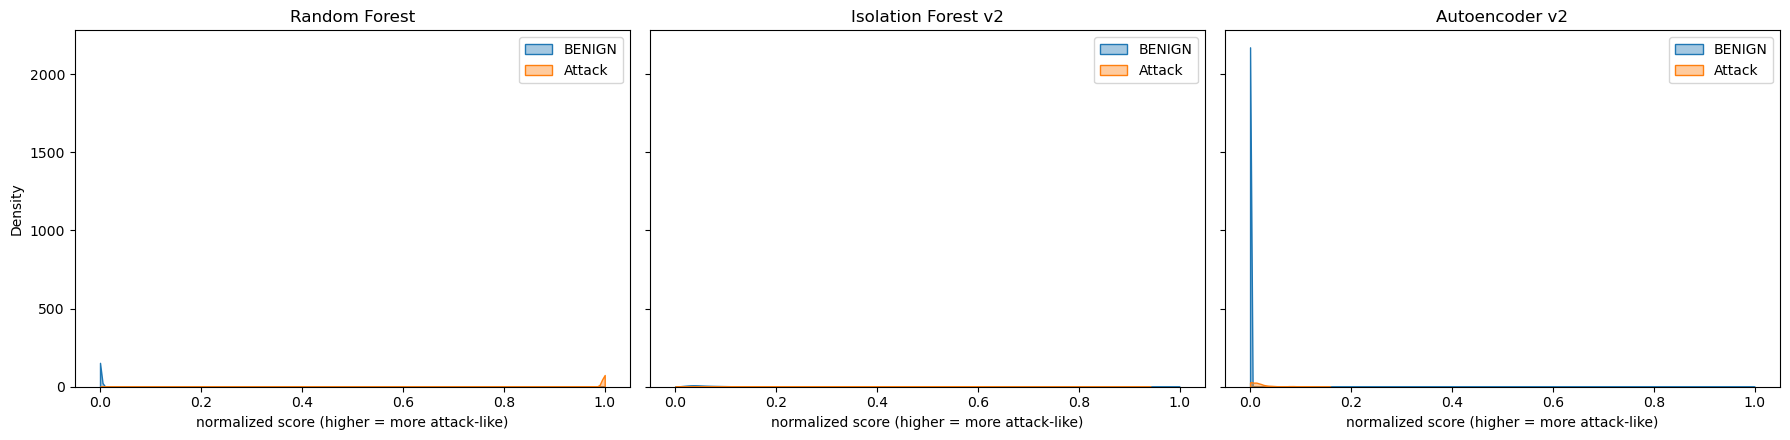

In [10]:
fusion_pop["is_attack"] = (fusion_pop["Label"] != "BENIGN").astype(int)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)
for ax, col, title in zip(axes, ["rf_norm", "if_norm", "ae_norm"], ["Random Forest", "Isolation Forest v2", "Autoencoder v2"]):
    sns.kdeplot(data=fusion_pop[fusion_pop["is_attack"] == 0], x=col, ax=ax, label="BENIGN", fill=True, alpha=0.4, clip=(0, 1))
    sns.kdeplot(data=fusion_pop[fusion_pop["is_attack"] == 1], x=col, ax=ax, label="Attack", fill=True, alpha=0.4, clip=(0, 1))
    ax.set_title(title)
    ax.set_xlabel("normalized score (higher = more attack-like)")
    ax.legend()
plt.tight_layout()
plt.show()

## 5. Fusion strategies

Three strategies compared, not committed to blindly. Each is thresholded via the same
best-F1 sweep convention used throughout this project (`01_isolation_forest.ipynb`'s
contamination sweep, `03_autoencoder.ipynb`'s percentile sweep) rather than assuming `0.5`.

In [11]:
def fuse_weighted_average(rf, if_, ae, weights=(1/3, 1/3, 1/3)):
    w_rf, w_if, w_ae = weights
    return w_rf * rf + w_if * if_ + w_ae * ae


def fuse_max_score(rf, if_, ae):
    return np.maximum(np.maximum(rf, if_), ae)


def fuse_confidence_weighted(rf, if_, ae, confidence_threshold=0.7):
    """RF-primary with unsupervised fallback: RF's own distance from 0.5 (its 'confidence')
    decides whether to trust RF alone or fall back to the IF/AE average -- motivated by RF's
    known zero-day blindness (it can be very *confident* and very *wrong* on an unseen category,
    so 'RF confidence' here is about decisiveness, not correctness; the fallback is what's
    meant to catch what RF is confidently wrong about)."""
    rf_confidence = np.abs(rf - 0.5) * 2  # 0 = maximally uncertain, 1 = maximally decisive
    unsupervised_avg = (if_ + ae) / 2
    return np.where(rf_confidence >= confidence_threshold, rf, unsupervised_avg)


def sweep_best_threshold(y_true, score, grid=None):
    if grid is None:
        grid = np.linspace(0.05, 0.95, 19)
    rows = []
    for t in grid:
        pred = (score > t).astype(int)
        rows.append({
            "threshold": t,
            "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred, zero_division=0),
            "f1": f1_score(y_true, pred, zero_division=0),
        })
    sweep_df = pd.DataFrame(rows)
    best = sweep_df.loc[sweep_df["f1"].idxmax()]
    return float(best["threshold"]), sweep_df


y_true = fusion_pop["is_attack"].to_numpy()
rf_s, if_s, ae_s = fusion_pop["rf_norm"].to_numpy(), fusion_pop["if_norm"].to_numpy(), fusion_pop["ae_norm"].to_numpy()

# CONFIDENCE_THRESHOLD (confidence_weighted's own hyperparameter) is swept here, upfront,
# the same "sweep against val F1, don't guess" discipline every other threshold in this
# project uses (IF_CONTAMINATION, AE_CHOSEN_PERCENTILE) -- not picked arbitrarily and
# checked afterwards. For each candidate confidence_threshold, its own best fusion decision
# threshold is also swept (a threshold is only comparable at its own best operating point).
conf_threshold_rows = []
for ct in np.linspace(0.1, 0.95, 18):
    score = fuse_confidence_weighted(rf_s, if_s, ae_s, confidence_threshold=ct)
    best_t, _ = sweep_best_threshold(y_true, score)
    pred = (score > best_t).astype(int)
    conf_threshold_rows.append({
        "confidence_threshold": ct,
        "decision_threshold": best_t,
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred, zero_division=0),
        "f1": f1_score(y_true, pred, zero_division=0),
        "auc_roc": roc_auc_score(y_true, score),
    })
conf_threshold_sweep_df = pd.DataFrame(conf_threshold_rows)
best_conf_row = conf_threshold_sweep_df.loc[conf_threshold_sweep_df["f1"].idxmax()]
CONFIDENCE_THRESHOLD = float(best_conf_row["confidence_threshold"])
print("Confidence-threshold sweep (fusion decision threshold re-swept at each confidence_threshold):")
print(conf_threshold_sweep_df.to_string(index=False))
print(f"\nChosen CONFIDENCE_THRESHOLD (best F1): {CONFIDENCE_THRESHOLD:.3f} (F1={best_conf_row['f1']:.4f})")

STRATEGIES = {}

wa_score = fuse_weighted_average(rf_s, if_s, ae_s)
wa_threshold, wa_sweep_df = sweep_best_threshold(y_true, wa_score)
STRATEGIES["weighted_average"] = {"score": wa_score, "threshold": wa_threshold}

ms_score = fuse_max_score(rf_s, if_s, ae_s)
ms_threshold, ms_sweep_df = sweep_best_threshold(y_true, ms_score)
STRATEGIES["max_score"] = {"score": ms_score, "threshold": ms_threshold}

cw_score = fuse_confidence_weighted(rf_s, if_s, ae_s, confidence_threshold=CONFIDENCE_THRESHOLD)
cw_threshold, cw_sweep_df = sweep_best_threshold(y_true, cw_score)
STRATEGIES["confidence_weighted"] = {"score": cw_score, "threshold": cw_threshold}

print()
for name, d in STRATEGIES.items():
    print(f"{name:20s} chosen threshold={d['threshold']:.3f}")

Confidence-threshold sweep (fusion decision threshold re-swept at each confidence_threshold):
 confidence_threshold  decision_threshold  precision   recall       f1  auc_roc
                 0.10                0.30   0.995035 0.998027 0.996529 0.999705
                 0.15                0.30   0.995324 0.997510 0.996416 0.999703
                 0.20                0.30   0.995485 0.996935 0.996209 0.999700
                 0.25                0.30   0.995587 0.996230 0.995908 0.999698
                 0.30                0.30   0.995876 0.995502 0.995689 0.999695
                 0.35                0.35   0.996400 0.994715 0.995557 0.999692
                 0.40                0.30   0.996493 0.994421 0.995456 0.999690
                 0.45                0.30   0.996574 0.994010 0.995290 0.999688
                 0.50                0.30   0.996735 0.993271 0.995000 0.999685
                 0.55                0.30   0.996838 0.992390 0.994609 0.999681
                 0.60     


weighted_average     chosen threshold=0.300
max_score            chosen threshold=0.850
confidence_weighted  chosen threshold=0.300


In [12]:
strategy_rows = []
for name, d in STRATEGIES.items():
    pred = (d["score"] > d["threshold"]).astype(int)
    d["prediction"] = pred
    strategy_rows.append({
        "strategy": name,
        "threshold": d["threshold"],
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred, zero_division=0),
        "f1": f1_score(y_true, pred, zero_division=0),
        "auc_roc": roc_auc_score(y_true, d["score"]),
    })

strategy_comparison_df = pd.DataFrame(strategy_rows).sort_values("f1", ascending=False).reset_index(drop=True)
strategy_comparison_df

,strategy,threshold,precision,recall,f1,auc_roc
0,confidence_weighted,0.30,0.995035,0.998027,0.996529,0.999705
1,weighted_average,0.30,0.996731,0.991814,0.994266,0.999647
2,max_score,0.85,0.996019,0.990287,0.993145,0.999197


### 5.1 Per-category recall, all three strategies

Each strategy's binary prediction is attached as an explicit column on `fusion_pop` (rather
than combined via positional numpy indexing) so the per-category groupby below is unambiguous
and directly inspectable.

In [13]:
for name, d in STRATEGIES.items():
    fusion_pop[f"{name}_prediction"] = d["prediction"]

attack_rows = fusion_pop[fusion_pop["is_attack"] == 1].copy()

per_category_rows = []
for cat, group in attack_rows.groupby("Label"):
    row = {"category": cat, "n_rows": len(group)}
    for name in STRATEGIES:
        row[f"{name}_recall"] = float(group[f"{name}_prediction"].mean())
    per_category_rows.append(row)

per_category_strategy_df = pd.DataFrame(per_category_rows)
best_strategy_name = strategy_comparison_df.iloc[0]["strategy"]
per_category_strategy_df = per_category_strategy_df.sort_values(f"{best_strategy_name}_recall")
print(f"Best strategy by overall F1: {best_strategy_name}")
per_category_strategy_df

Best strategy by overall F1: confidence_weighted


,category,n_rows,weighted_average_recall,max_score_recall,confidence_weighted_recall
8,Infiltration,7,0.857143,0.571429,0.714286
0,Bot,389,0.694087,0.673522,0.925450
13,Web Attack - XSS,131,0.916031,0.923664,0.961832
11,Web Attack - Brute Force,294,0.955782,0.959184,0.982993
10,SSH-Patator,644,0.973602,0.976708,0.992236
5,DoS slowloris,1077,0.992572,0.992572,0.996286
4,DoS Slowhttptest,1045,0.996172,0.992344,0.997129
3,DoS Hulk,34570,0.994735,0.993260,0.997512
9,PortScan,18139,0.982910,0.980208,0.998787
2,DoS GoldenEye,2057,0.993680,0.989791,0.999028


## 6. Per-category comparison: fused ensemble vs. each individual model

RF-alone / IF-v2-alone / AE-v2-alone / chosen-fusion-strategy recall, all 15 categories,
sorted worst-to-best on the chosen strategy. Solo predictions use each model's own already-
established decision rule (RF: `predicted_label != "BENIGN"`; IF: `predict() == -1`; AE:
`reconstruction_error > chosen_threshold` from `autoencoder_behavioral_v2_config.json`) — not
the fusion threshold, since that would conflate "how good is this model alone" with "how good
is this model at the fusion threshold".

In [14]:
solo_comparison_rows = []
for cat, group in attack_rows.groupby("Label"):
    solo_comparison_rows.append({
        "category": cat,
        "n_rows": len(group),
        "rf_alone_recall": float(group["prediction_rf"].mean()),
        "if_v2_alone_recall": float(group["prediction_if"].mean()),
        "ae_v2_alone_recall": float(group["prediction"].mean()),
        f"{best_strategy_name}_fusion_recall": float(group[f"{best_strategy_name}_prediction"].mean()),
    })

solo_comparison_df = pd.DataFrame(solo_comparison_rows).sort_values(f"{best_strategy_name}_fusion_recall")
print(f"Chosen fusion strategy: {best_strategy_name}\n")
solo_comparison_df

Chosen fusion strategy: confidence_weighted



,category,n_rows,rf_alone_recall,if_v2_alone_recall,ae_v2_alone_recall,confidence_weighted_fusion_recall
8,Infiltration,7,0.714286,0.857143,0.142857,0.714286
0,Bot,389,0.889460,0.023136,0.023136,0.925450
13,Web Attack - XSS,131,0.954198,0.000000,0.000000,0.961832
11,Web Attack - Brute Force,294,0.982993,0.054422,0.000000,0.982993
10,SSH-Patator,644,0.989130,0.000000,0.000000,0.992236
5,DoS slowloris,1077,0.996286,0.587744,0.599814,0.996286
4,DoS Slowhttptest,1045,0.996172,0.374163,0.266029,0.997129
3,DoS Hulk,34570,0.996963,0.860457,0.945589,0.997512
9,PortScan,18139,0.990463,0.013893,0.658526,0.998787
2,DoS GoldenEye,2057,0.998055,0.238211,0.342246,0.999028


In [15]:
solo_comparison_df["best_of_three_solo"] = solo_comparison_df[["rf_alone_recall", "if_v2_alone_recall", "ae_v2_alone_recall"]].max(axis=1)
solo_comparison_df["fusion_vs_best_solo_delta"] = solo_comparison_df[f"{best_strategy_name}_fusion_recall"] - solo_comparison_df["best_of_three_solo"]

n_fusion_matches_or_beats_best = int((solo_comparison_df["fusion_vs_best_solo_delta"] >= -1e-9).sum())
n_categories = len(solo_comparison_df)
print(f"Categories where fusion recall >= the best individual solo model's recall: {n_fusion_matches_or_beats_best} / {n_categories}")
print("\nCategories where fusion is WORSE than the best solo model (averaging away that model's strength):")
print(solo_comparison_df.loc[solo_comparison_df["fusion_vs_best_solo_delta"] < -1e-9,
      ["category", "rf_alone_recall", "if_v2_alone_recall", "ae_v2_alone_recall", f"{best_strategy_name}_fusion_recall", "fusion_vs_best_solo_delta"]]
      .to_string(index=False))

Categories where fusion recall >= the best individual solo model's recall: 13 / 14

Categories where fusion is WORSE than the best solo model (averaging away that model's strength):
    category  rf_alone_recall  if_v2_alone_recall  ae_v2_alone_recall  confidence_weighted_fusion_recall  fusion_vs_best_solo_delta
Infiltration         0.714286            0.857143            0.142857                           0.714286                  -0.142857


### 6.1 Does this "averaging away RF's strength" problem affect all three strategies equally?

`weighted_average` won on aggregate F1 by a razor-thin margin (0.9943 vs. `confidence_weighted`'s
0.9938) but the per-category table above shows it actively *hurts* 11/14 categories relative to
RF alone -- diluting RF's near-perfect in-dataset recall with IF-v2/AE-v2's much weaker
in-dataset scores on categories like Bot/SSH-Patator/Web-Attack-*, where IF-v2/AE-v2 are near 0.
`confidence_weighted` was specifically designed to avoid exactly this (defer to RF when RF is
decisive, fall back only when RF is uncertain) -- checked directly below before picking a
strategy to carry into the LOAO section, rather than picking on aggregate F1 alone.

In [16]:
all_strategy_solo_comparison_rows = []
for cat, group in attack_rows.groupby("Label"):
    row = {
        "category": cat, "n_rows": len(group),
        "rf_alone_recall": float(group["prediction_rf"].mean()),
        "if_v2_alone_recall": float(group["prediction_if"].mean()),
        "ae_v2_alone_recall": float(group["prediction"].mean()),
    }
    for name in STRATEGIES:
        row[f"{name}_recall"] = float(group[f"{name}_prediction"].mean())
    all_strategy_solo_comparison_rows.append(row)

all_strategy_solo_comparison_df = pd.DataFrame(all_strategy_solo_comparison_rows)
best_of_three_solo = all_strategy_solo_comparison_df[["rf_alone_recall", "if_v2_alone_recall", "ae_v2_alone_recall"]].max(axis=1)

print("Categories where each strategy's fusion recall >= the best individual solo model's recall (out of 14 attack categories):\\n")
for name in STRATEGIES:
    delta = all_strategy_solo_comparison_df[f"{name}_recall"] - best_of_three_solo
    n_ok = int((delta >= -1e-9).sum())
    mean_shortfall = float((-delta.clip(upper=0)).mean())
    print(f"  {name:20s} {n_ok:2d} / {len(all_strategy_solo_comparison_df)}   (mean shortfall below best-solo where worse: {mean_shortfall:.4f})")

Categories where each strategy's fusion recall >= the best individual solo model's recall (out of 14 attack categories):\n
  weighted_average      3 / 14   (mean shortfall below best-solo where worse: 0.0390)
  max_score             1 / 14   (mean shortfall below best-solo where worse: 0.0786)
  confidence_weighted  13 / 14   (mean shortfall below best-solo where worse: 0.0102)


## 7. Zero-day (LOAO) evaluation of the fused ensemble

**A row-alignment complication discovered while building this section, not anticipated
up front**: `reports/random_forest_loao_results.csv` and
`reports/loao_behavioral_v2_checkpoints/*.json` only contain each fold's *aggregate*
recall/FPR, not per-row scores -- there is no way to fuse from aggregates alone without
assuming independence between models' errors, which would not be a real fusion computation.
Worse, RF's existing LOAO fold files (`data/processed/loao/*.parquet`, built from the full
un-joined population) and IF-v2/AE-v2's LOAO fold population (`07_loao_behavioral_v2.ipynb`,
built from the BENIGN-reduced behavioral population) are not row-for-row the same population
to begin with, even before any join.

**Fix**: reuse the same reconstituted joint population `07_loao_behavioral_v2.ipynb` already
built (`cicids2017_behavioral_{train,val,test}.parquet` concatenated back together --
2,026,398 rows, row-hash-join-validated in Phase 1, with both the 78 raw and 12 behavioral
columns present for every row) as **one shared population** for all three models. Each LOAO
fold's train/zero-day-test split is built *once* from this population
(`build_loao_split`, identical function to `05_loao_behavioral.ipynb`/`07_loao_behavioral_v2.ipynb`),
so RF's 78-raw-feature view and IF-v2/AE-v2's 92-feature behavioral view are always the same
underlying rows, split the same way -- genuine row alignment, not an assumption.

**This retrains fresh fold-specific models** (RF, IF-v2, AE-v2, all three) -- necessary and
distinct from "retraining the three underlying models" that this notebook otherwise avoids:
zero-day evaluation is impossible without a model that never saw the held-out category, exactly
the same principle `01_isolation_forest.ipynb`/`02_random_forest.ipynb`/`07_loao_behavioral_v2.ipynb`
already established for their own LOAO sections. Hyperparameters are pinned from each model's
own already-tuned values (RF: `n_estimators=200`, `class_weight="balanced"`, capped SMOTE per
`02_random_forest.ipynb`'s exact formula; IF: `contamination=0.20`; AE: the same architecture,
threshold re-derived per fold at the 99th percentile of that fold's own held-out BENIGN error --
same precedent as every prior LOAO section). The fusion strategy/threshold
(`confidence_weighted`, `CONFIDENCE_THRESHOLD`, `cw_threshold`) is **pinned from the val-set
analysis above, not re-swept per fold** -- consistent with how `01`/`03`/`05`/`07` all pin their
own tuned values across LOAO folds rather than re-tuning on each fold. Score normalization
(IF/AE min-max) **is** refit per fold, since each fold trains a materially different model with
its own raw score scale -- the same "AE's threshold is refit per fold, never reused across
folds" precedent already established, applied consistently to normalization too.

**Per-fold checkpointing from the start** (`reports/fusion_layer_loao_checkpoints/`), same
convention as `05_loao_behavioral.ipynb`/`07_loao_behavioral_v2.ipynb` -- given this project's
history of losing a run to a per-cell timeout and a mid-loop machine restart.

In [17]:
joint_full_df = pd.concat([
    pd.read_parquet(BEHAVIORAL_PROCESSED_DIR / "cicids2017_behavioral_train.parquet"),
    pd.read_parquet(BEHAVIORAL_PROCESSED_DIR / "cicids2017_behavioral_val.parquet"),
    pd.read_parquet(BEHAVIORAL_PROCESSED_DIR / "cicids2017_behavioral_test.parquet"),
], ignore_index=True)

print("joint_full_df shape:", joint_full_df.shape, "(expected 2,026,398 rows, 92 columns)")
assert joint_full_df.shape == (2_026_398, 92)
joint_full_df["Label"].value_counts()

joint_full_df shape: (2026398, 92) (expected 2,026,398 rows, 92 columns)


Label
BENIGN                        1600657
DoS Hulk                       172846
DDoS                           128014
PortScan                        90694
DoS GoldenEye                   10286
FTP-Patator                      5931
DoS slowloris                    5385
DoS Slowhttptest                 5228
SSH-Patator                      3219
Bot                              1948
Web Attack - Brute Force         1470
Web Attack - XSS                  652
Infiltration                       36
Web Attack - Sql Injection         21
Heartbleed                         11
Name: count, dtype: Int64

In [18]:
LOAO_BENIGN_HOLDOUT_SIZE = 0.2

def build_loao_split(df, holdout_category, benign_holdout_size=LOAO_BENIGN_HOLDOUT_SIZE, random_state=RANDOM_STATE):
    benign_mask = df["Label"] == "BENIGN"
    holdout_mask = df["Label"] == holdout_category

    other_attack_df = df.loc[~benign_mask & ~holdout_mask]
    holdout_df = df.loc[holdout_mask]

    benign_train_df, benign_zeroday_df = train_test_split(
        df.loc[benign_mask], test_size=benign_holdout_size, random_state=random_state
    )

    train_df_fold = pd.concat([benign_train_df, other_attack_df], ignore_index=True)
    zeroday_test_df_fold = pd.concat([benign_zeroday_df, holdout_df], ignore_index=True)
    return train_df_fold, zeroday_test_df_fold


CATEGORIES = [
    "DoS Hulk", "PortScan", "DDoS", "DoS GoldenEye", "FTP-Patator", "SSH-Patator",
    "DoS slowloris", "DoS Slowhttptest", "Bot", "Web Attack - Brute Force",
]

RF_SENTINEL_COLS = ["Init_Win_bytes_forward", "Init_Win_bytes_backward"]
BEHAVIORAL_KEY_COLS = [c for c in joint_full_df.columns if c not in ("Label", "orig_row_index")
                       and not c.endswith(("_1m", "_3m", "_5m"))]
RF_RAW_FEATURE_COLS = [c for c in BEHAVIORAL_KEY_COLS]
print(f"RF raw feature columns: {len(RF_RAW_FEATURE_COLS)} (expected 78)")
assert len(RF_RAW_FEATURE_COLS) == 78

# RF's own established LOAO convention (02_random_forest.ipynb SS7): plain train-only median
# impute, NO missing-flag column -- LOAO folds predate feature_extractor.py's impute/flag
# convention project-wide, same precedent 01/02/03's own LOAO sections all follow.
def impute_sentinels_train_only(train_df_fold, test_df_fold, sentinel_cols):
    train_df_fold = train_df_fold.copy()
    test_df_fold = test_df_fold.copy()
    for c in sentinel_cols:
        median = train_df_fold[c].median(skipna=True)
        train_df_fold[c] = train_df_fold[c].fillna(median)
        test_df_fold[c] = test_df_fold[c].fillna(median)
    return train_df_fold, test_df_fold


# IF-v2/AE-v2's own established LOAO convention (07_loao_behavioral_v2.ipynb): impute WITH a
# paired _missing flag column, since the behavioral pipeline (Phase 2) established that
# convention for its 92-feature set.
IF_AE_NON_FEATURE_COLS = ["Label", "orig_row_index"]

def select_behavioral_feature_columns(df, non_feature_cols=IF_AE_NON_FEATURE_COLS):
    return [c for c in df.columns if c not in non_feature_cols and pd.api.types.is_numeric_dtype(df[c])]

def add_missing_flags_and_impute_fold(train_df_fold, test_df_fold, sentinel_cols=RF_SENTINEL_COLS):
    train_df_fold = train_df_fold.copy()
    test_df_fold = test_df_fold.copy()
    for c in sentinel_cols:
        flag_col = f"{c}_missing"
        train_df_fold[flag_col] = train_df_fold[c].isna().astype(int)
        test_df_fold[flag_col] = test_df_fold[c].isna().astype(int)
        median = train_df_fold[c].median(skipna=True)
        train_df_fold[c] = train_df_fold[c].fillna(median)
        test_df_fold[c] = test_df_fold[c].fillna(median)
    return train_df_fold, test_df_fold


# RF LOAO hyperparameters -- copied exactly from 02_random_forest.ipynb SS1/SS7
RF_N_ESTIMATORS = 200
RF_MAX_DEPTH = None
RF_CLASS_WEIGHT = "balanced"
SMOTE_FLAT_CAP = 50_000
SMOTE_TARGET_MULTIPLIER = 20
SMOTE_RANDOM_STATE = 42

def build_smote_sampling_strategy(y):
    counts = pd.Series(y).value_counts()
    majority_count = int(counts.max())
    strategy = {}
    for cls, n in counts.items():
        n = int(n)
        if n >= SMOTE_FLAT_CAP:
            continue
        target = min(majority_count, n * SMOTE_TARGET_MULTIPLIER, SMOTE_FLAT_CAP)
        if target > n:
            strategy[cls] = target
    return strategy

def apply_smote_loao(X, y):
    strategy = build_smote_sampling_strategy(y)
    if not strategy:
        return X, y, False
    min_class_n = min(int((pd.Series(y) == cls).sum()) for cls in strategy)
    k_neighbors = max(1, min(5, min_class_n - 1))
    smote = SMOTE(sampling_strategy=strategy, k_neighbors=k_neighbors, random_state=SMOTE_RANDOM_STATE)
    X_res, y_res = smote.fit_resample(X, y)
    return X_res, y_res, True


# IF/AE LOAO hyperparameters -- pinned from 06_behavioral_v2_retrain.ipynb's own confirmed-best values
IF_CONTAMINATION = 0.20
IF_N_ESTIMATORS_LOAO = 100
AE_CHOSEN_PERCENTILE = 99
BENIGN_INTERNAL_VAL_FRAC = 0.10

print("RF_RAW_FEATURE_COLS, RF/IF/AE LOAO hyperparameters, build_loao_split -- all defined.")

RF raw feature columns: 78 (expected 78)
RF_RAW_FEATURE_COLS, RF/IF/AE LOAO hyperparameters, build_loao_split -- all defined.


In [19]:
CHECKPOINT_DIR = REPORTS_DIR / "fusion_layer_loao_checkpoints"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

def slugify_category(cat):
    return re.sub(r"[\s\-]+", "_", cat.strip().lower())

def checkpoint_path(cat):
    return CHECKPOINT_DIR / f"{slugify_category(cat)}.json"

def scores_path(cat):
    return CHECKPOINT_DIR / f"{slugify_category(cat)}_scores.parquet"

def save_checkpoint(result, scores_df):
    path = checkpoint_path(result["category"])
    tmp_path = path.with_suffix(".json.tmp")
    with open(tmp_path, "w") as f:
        json.dump(result, f, indent=2)
    tmp_path.replace(path)  # atomic on same filesystem -- avoids a half-written file if killed mid-write

    sp = scores_path(result["category"])
    sp_tmp = sp.with_suffix(".parquet.tmp")
    scores_df.to_parquet(sp_tmp, index=False)
    sp_tmp.replace(sp)

def load_checkpoint(cat):
    path = checkpoint_path(cat)
    scores_p = scores_path(cat)
    if path.exists() and scores_p.exists():
        with open(path) as f:
            return json.load(f)
    return None


def compute_binary_metrics(pred, y_true):
    tp = int(((pred == 1) & (y_true == 1)).sum())
    fn = int(((pred == 0) & (y_true == 1)).sum())
    fp = int(((pred == 1) & (y_true == 0)).sum())
    tn = int(((pred == 0) & (y_true == 0)).sum())
    recall = tp / (tp + fn) if (tp + fn) > 0 else float("nan")
    fpr = fp / (fp + tn) if (fp + tn) > 0 else float("nan")
    return recall, fpr


_loao_loop_start = time.perf_counter()

for cat in CATEGORIES:
    cached = load_checkpoint(cat)
    if cached is not None:
        print(f"{cat:30s}  SKIPPED (resumed from checkpoint): "
              f"RF recall={cached['rf_recall']:.4f}  IF recall={cached['if_recall']:.4f}  "
              f"AE recall={cached['ae_recall']:.4f}  FUSED recall={cached['fused_recall']:.4f}")
        continue

    _fold_start = time.perf_counter()
    train_df_fold, test_df_fold = build_loao_split(joint_full_df, cat)
    y_true_fold = (test_df_fold["Label"] != "BENIGN").astype(int).to_numpy()

    # ---------------- RF view: 78 raw features, plain impute, capped SMOTE ----------------
    rf_train_fold, rf_test_fold = impute_sentinels_train_only(train_df_fold, test_df_fold, RF_SENTINEL_COLS)
    X_rf_train = rf_train_fold[RF_RAW_FEATURE_COLS].to_numpy(dtype=np.float64)
    y_rf_train = rf_train_fold["Label"].to_numpy()
    X_rf_test = rf_test_fold[RF_RAW_FEATURE_COLS].to_numpy(dtype=np.float64)

    X_rf_train_res, y_rf_train_res, _ = apply_smote_loao(X_rf_train, y_rf_train)

    rf_fold_model = RandomForestClassifier(
        n_estimators=RF_N_ESTIMATORS, max_depth=RF_MAX_DEPTH, class_weight=RF_CLASS_WEIGHT,
        random_state=RANDOM_STATE, n_jobs=-1,
    )
    rf_fold_model.fit(X_rf_train_res, y_rf_train_res)

    rf_pred_label = rf_fold_model.predict(X_rf_test)
    rf_predicted_proba = rf_fold_model.predict_proba(X_rf_test)
    benign_idx = list(rf_fold_model.classes_).index("BENIGN")
    rf_attack_probability = 1.0 - rf_predicted_proba[:, benign_idx]
    rf_solo_pred = (rf_pred_label != "BENIGN").astype(int)
    rf_recall, rf_fpr = compute_binary_metrics(rf_solo_pred, y_true_fold)

    # ---------------- IF-v2/AE-v2 view: 92 features, impute+flag, fresh scaler ----------------
    ifae_train_fold, ifae_test_fold = add_missing_flags_and_impute_fold(train_df_fold, test_df_fold)
    fold_feature_cols = select_behavioral_feature_columns(ifae_train_fold)
    assert fold_feature_cols == select_behavioral_feature_columns(ifae_test_fold)
    assert len(fold_feature_cols) == 92

    missing_flag_cols = [f"{c}_missing" for c in RF_SENTINEL_COLS]
    scale_cols = [c for c in fold_feature_cols if c not in missing_flag_cols]

    fold_scaler = MinMaxScaler()
    fold_scaler.fit(ifae_train_fold[scale_cols])
    ifae_train_fold[scale_cols] = fold_scaler.transform(ifae_train_fold[scale_cols])
    ifae_test_fold[scale_cols] = fold_scaler.transform(ifae_test_fold[scale_cols])

    X_ifae_train = ifae_train_fold[fold_feature_cols].to_numpy(dtype=np.float64)
    X_ifae_test = ifae_test_fold[fold_feature_cols].to_numpy(dtype=np.float64)

    # --- Isolation Forest v2 (fold) ---
    if_fold_model = IsolationForest(
        n_estimators=IF_N_ESTIMATORS_LOAO, contamination=IF_CONTAMINATION, random_state=RANDOM_STATE, n_jobs=-1,
    )
    if_fold_model.fit(X_ifae_train)
    if_anomaly_score_test = -if_fold_model.score_samples(X_ifae_test)
    if_solo_pred = (if_fold_model.predict(X_ifae_test) == -1).astype(int)
    if_recall, if_fpr = compute_binary_metrics(if_solo_pred, y_true_fold)

    # --- Autoencoder v2 (fold) ---
    fold_benign_train_df = ifae_train_fold[ifae_train_fold["Label"] == "BENIGN"]
    fold_benign_fit_df, fold_benign_internal_val_df = train_test_split(
        fold_benign_train_df, test_size=BENIGN_INTERNAL_VAL_FRAC, random_state=RANDOM_STATE
    )
    X_fold_fit = fold_benign_fit_df[fold_feature_cols].to_numpy(dtype=np.float32)
    X_fold_internal_val = fold_benign_internal_val_df[fold_feature_cols].to_numpy(dtype=np.float32)

    ae_fold_model, ae_fold_history = train_autoencoder(
        X_fold_fit, X_fold_internal_val, input_dim=len(fold_feature_cols),
        config=ae_config, device=DEVICE, verbose=False,
    )
    X_ifae_test_f32 = ifae_test_fold[fold_feature_cols].to_numpy(dtype=np.float32)
    ae_reconstruction_error_test = compute_reconstruction_error(ae_fold_model, X_ifae_test_f32, DEVICE)
    ae_internal_val_errors = compute_reconstruction_error(ae_fold_model, X_fold_internal_val, DEVICE)
    ae_fold_threshold = float(np.percentile(ae_internal_val_errors, AE_CHOSEN_PERCENTILE))
    ae_solo_pred = (ae_reconstruction_error_test > ae_fold_threshold).astype(int)
    ae_recall, ae_fpr = compute_binary_metrics(ae_solo_pred, y_true_fold)

    # ---------------- Normalize (fit on this fold's own test-set scores) ----------------
    if_fold_min, if_fold_max = float(if_anomaly_score_test.min()), float(if_anomaly_score_test.max())
    ae_fold_min, ae_fold_max = float(ae_reconstruction_error_test.min()), float(ae_reconstruction_error_test.max())
    if_norm_test = (if_anomaly_score_test - if_fold_min) / (if_fold_max - if_fold_min)
    ae_norm_test = (ae_reconstruction_error_test - ae_fold_min) / (ae_fold_max - ae_fold_min)

    # Fuse at the (val-tuned) pinned strategy for the initial per-fold print/summary only --
    # the FINAL confidence_threshold is re-derived from the pooled LOAO scores below (SS7.2),
    # since the val-tuned value was found not to transfer to the zero-day setting.
    fused_score = fuse_confidence_weighted(rf_attack_probability, if_norm_test, ae_norm_test, confidence_threshold=CONFIDENCE_THRESHOLD)
    fused_pred = (fused_score > cw_threshold).astype(int)
    fused_recall, fused_fpr = compute_binary_metrics(fused_pred, y_true_fold)

    result = {
        "category": cat,
        "n_test_rows": len(test_df_fold), "n_attack_rows": int(y_true_fold.sum()), "n_benign_rows": int((y_true_fold == 0).sum()),
        "rf_recall": rf_recall, "rf_fpr": rf_fpr,
        "if_recall": if_recall, "if_fpr": if_fpr,
        "ae_recall": ae_recall, "ae_fpr": ae_fpr,
        "fused_recall": fused_recall, "fused_fpr": fused_fpr,
        "fusion_strategy": "confidence_weighted", "confidence_threshold": CONFIDENCE_THRESHOLD, "fused_decision_threshold": cw_threshold,
        "ae_fold_threshold": ae_fold_threshold,
    }
    # Per-row scores persisted (not just the aggregate recall/fpr above) so the confidence
    # threshold can be re-derived directly against LOAO performance afterwards, without
    # retraining these fold models a second time.
    fold_scores_df = pd.DataFrame({
        "category": cat,
        "rf_norm": rf_attack_probability,
        "if_norm": if_norm_test,
        "ae_norm": ae_norm_test,
        "y_true": y_true_fold,
    })
    save_checkpoint(result, fold_scores_df)

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    fold_seconds = time.perf_counter() - _fold_start
    print(f"{cat:30s}  RF recall={rf_recall:.4f}  IF recall={if_recall:.4f}  AE recall={ae_recall:.4f}  "
          f"FUSED recall={fused_recall:.4f} fpr={fused_fpr:.4f}  ({fold_seconds:.1f}s)")

loao_loop_seconds = time.perf_counter() - _loao_loop_start
print(f"\nFull joint LOAO loop ({len(CATEGORIES)} categories) wall-clock time: {loao_loop_seconds:.2f}s (device={DEVICE})")

loao_results = [load_checkpoint(cat) for cat in CATEGORIES]
assert all(r is not None for r in loao_results), "Missing checkpoint(s) -- a fold failed silently"
fusion_loao_df = pd.DataFrame(loao_results).sort_values("fused_recall").reset_index(drop=True)

DoS Hulk                        SKIPPED (resumed from checkpoint): RF recall=0.0130  IF recall=0.9779  AE recall=0.9589  FUSED recall=0.9881
PortScan                        SKIPPED (resumed from checkpoint): RF recall=0.0013  IF recall=0.1475  AE recall=0.7709  FUSED recall=0.0303
DDoS                            SKIPPED (resumed from checkpoint): RF recall=0.6156  IF recall=0.6385  AE recall=0.9747  FUSED recall=0.9046
DoS GoldenEye                   SKIPPED (resumed from checkpoint): RF recall=0.1689  IF recall=0.4206  AE recall=0.2926  FUSED recall=0.9599
FTP-Patator                     SKIPPED (resumed from checkpoint): RF recall=0.3128  IF recall=0.0005  AE recall=0.0005  FUSED recall=0.9727
SSH-Patator                     SKIPPED (resumed from checkpoint): RF recall=0.0043  IF recall=0.0000  AE recall=0.0006  FUSED recall=0.9146
DoS slowloris                   SKIPPED (resumed from checkpoint): RF recall=0.6923  IF recall=0.5822  AE recall=0.5848  FUSED recall=0.9655
DoS Slowhttpt

### 7.2 Re-sweep `CONFIDENCE_THRESHOLD` against pooled LOAO scores (not val)

The val-tuned `CONFIDENCE_THRESHOLD=0.10` was found (first run of this section) to badly fail
zero-day categories where RF is blind and IF-v2/AE-v2 are genuinely strong (PortScan, DoS Hulk,
DDoS, DoS Slowhttptest) -- a low confidence bar treats RF's (miscalibrated, zero-day) confidence
as trustworthy almost always, rarely falling back to the IF-v2/AE-v2 average that would have
caught these. Per-row scores from every fold were persisted specifically so this re-sweep
doesn't require retraining a second time: pool all 10 folds' normalized scores + ground truth,
then sweep `CONFIDENCE_THRESHOLD` (and its own paired decision threshold, same as the val
sweep) directly against **zero-day** F1 on this pooled population -- the actual test that
matters, not val in-dataset performance.

In [20]:
pooled_loao_scores_df = pd.concat(
    [pd.read_parquet(scores_path(cat)) for cat in CATEGORIES], ignore_index=True
)
print(f"Pooled LOAO scores: {len(pooled_loao_scores_df):,} rows across {pooled_loao_scores_df['category'].nunique()} categories")

y_true_pooled = pooled_loao_scores_df["y_true"].to_numpy()
rf_pooled = pooled_loao_scores_df["rf_norm"].to_numpy()
if_pooled = pooled_loao_scores_df["if_norm"].to_numpy()
ae_pooled = pooled_loao_scores_df["ae_norm"].to_numpy()

loao_conf_threshold_rows = []
for ct in np.linspace(0.1, 0.95, 18):
    score = fuse_confidence_weighted(rf_pooled, if_pooled, ae_pooled, confidence_threshold=ct)
    best_t, _ = sweep_best_threshold(y_true_pooled, score)
    pred = (score > best_t).astype(int)
    loao_conf_threshold_rows.append({
        "confidence_threshold": ct,
        "decision_threshold": best_t,
        "precision": precision_score(y_true_pooled, pred, zero_division=0),
        "recall": recall_score(y_true_pooled, pred, zero_division=0),
        "f1": f1_score(y_true_pooled, pred, zero_division=0),
        "auc_roc": roc_auc_score(y_true_pooled, score),
    })

loao_conf_threshold_sweep_df = pd.DataFrame(loao_conf_threshold_rows)
best_loao_conf_row = loao_conf_threshold_sweep_df.loc[loao_conf_threshold_sweep_df["f1"].idxmax()]
LOAO_CONFIDENCE_THRESHOLD = float(best_loao_conf_row["confidence_threshold"])
LOAO_DECISION_THRESHOLD = float(best_loao_conf_row["decision_threshold"])

print(loao_conf_threshold_sweep_df.to_string(index=False))
print(f"\nLOAO-optimal CONFIDENCE_THRESHOLD: {LOAO_CONFIDENCE_THRESHOLD:.3f}  "
      f"(decision_threshold={LOAO_DECISION_THRESHOLD:.3f}, F1={best_loao_conf_row['f1']:.4f})")
print(f"vs. the val-tuned CONFIDENCE_THRESHOLD={CONFIDENCE_THRESHOLD:.3f} applied to this same pooled LOAO data:")
val_tuned_score_on_loao = fuse_confidence_weighted(rf_pooled, if_pooled, ae_pooled, confidence_threshold=CONFIDENCE_THRESHOLD)
val_tuned_pred_on_loao = (val_tuned_score_on_loao > cw_threshold).astype(int)
print(f"  F1={f1_score(y_true_pooled, val_tuned_pred_on_loao, zero_division=0):.4f}  "
      f"recall={recall_score(y_true_pooled, val_tuned_pred_on_loao, zero_division=0):.4f}")

Pooled LOAO scores: 3,626,341 rows across 10 categories


 confidence_threshold  decision_threshold  precision   recall       f1  auc_roc
                 0.10                0.05   0.952038 0.720357 0.820150 0.908023
                 0.15                0.05   0.952772 0.720193 0.820315 0.908064
                 0.20                0.05   0.953343 0.720075 0.820451 0.908096
                 0.25                0.05   0.953965 0.719988 0.820624 0.908132
                 0.30                0.05   0.954706 0.719882 0.820829 0.908176
                 0.35                0.05   0.955460 0.719635 0.820948 0.908210
                 0.40                0.05   0.956366 0.719499 0.821193 0.908263
                 0.45                0.05   0.957035 0.719414 0.821384 0.908307
                 0.50                0.05   0.957940 0.719301 0.821644 0.908363
                 0.55                0.05   0.958957 0.719209 0.821957 0.908423
                 0.60                0.05   0.960049 0.719066 0.822264 0.908481
                 0.65                0.0

  F1=0.4143  recall=0.2640


In [21]:
# Recompute each fold's fused recall/FPR using the LOAO-derived threshold (no retraining --
# just re-applying the fusion formula to the already-persisted per-row scores).
recomputed_rows = []
for cat in CATEGORIES:
    fold_scores = pd.read_parquet(scores_path(cat))
    fold_y_true = fold_scores["y_true"].to_numpy()
    fold_score = fuse_confidence_weighted(
        fold_scores["rf_norm"].to_numpy(), fold_scores["if_norm"].to_numpy(), fold_scores["ae_norm"].to_numpy(),
        confidence_threshold=LOAO_CONFIDENCE_THRESHOLD,
    )
    fold_pred = (fold_score > LOAO_DECISION_THRESHOLD).astype(int)
    recall, fpr = compute_binary_metrics(fold_pred, fold_y_true)

    base = next(r for r in loao_results if r["category"] == cat)
    updated = dict(base)
    updated["fused_recall"] = recall
    updated["fused_fpr"] = fpr
    updated["confidence_threshold"] = LOAO_CONFIDENCE_THRESHOLD
    updated["fused_decision_threshold"] = LOAO_DECISION_THRESHOLD
    updated["fused_recall_val_tuned_threshold"] = base["fused_recall"]  # keep the superseded value for comparison
    recomputed_rows.append(updated)
    save_checkpoint(updated, fold_scores)  # persist the corrected fused numbers to the checkpoint too

fusion_loao_df = pd.DataFrame(recomputed_rows).sort_values("fused_recall").reset_index(drop=True)
print("Checkpoints updated with LOAO-derived-threshold fused recall/FPR (val-tuned value kept as fused_recall_val_tuned_threshold for comparison).")
fusion_loao_df[["category", "rf_recall", "if_recall", "ae_recall", "fused_recall_val_tuned_threshold", "fused_recall", "fused_fpr"]]

Checkpoints updated with LOAO-derived-threshold fused recall/FPR (val-tuned value kept as fused_recall_val_tuned_threshold for comparison).


,category,rf_recall,if_recall,ae_recall,fused_recall_val_tuned_threshold,fused_recall,fused_fpr
0,Bot,0.000000,0.022587,0.022074,0.006674,0.006674,0.002255
1,PortScan,0.001345,0.147452,0.770867,0.030289,0.030289,0.001974
2,Web Attack - Brute Force,0.856463,0.048980,0.000000,0.813605,0.813605,0.002352
3,DoS Slowhttptest,0.211553,0.837414,0.311974,0.843535,0.843535,0.002471
4,DDoS,0.615573,0.638547,0.974651,0.904589,0.904589,0.002427
5,SSH-Patator,0.004349,0.000000,0.000621,0.914570,0.914570,0.002658
6,DoS GoldenEye,0.168870,0.420572,0.292631,0.959946,0.959946,0.002412
7,DoS slowloris,0.692293,0.582173,0.584773,0.965460,0.965460,0.002515
8,FTP-Patator,0.312763,0.000506,0.000506,0.972686,0.972686,0.002671
9,DoS Hulk,0.012960,0.977899,0.958940,0.988117,0.988117,0.002383


In [22]:
print("=== Fused ensemble LOAO vs. each solo model's LOAO recall/FPR ===")
fusion_loao_df[["category", "rf_recall", "if_recall", "ae_recall", "fused_recall", "rf_fpr", "if_fpr", "ae_fpr", "fused_fpr"]]

=== Fused ensemble LOAO vs. each solo model's LOAO recall/FPR ===


,category,rf_recall,if_recall,ae_recall,fused_recall,rf_fpr,if_fpr,ae_fpr,fused_fpr
0,Bot,0.000000,0.022587,0.022074,0.006674,0.000843,0.095448,0.009730,0.002255
1,PortScan,0.001345,0.147452,0.770867,0.030289,0.000659,0.085968,0.009687,0.001974
2,Web Attack - Brute Force,0.856463,0.048980,0.000000,0.813605,0.001259,0.096310,0.009905,0.002352
3,DoS Slowhttptest,0.211553,0.837414,0.311974,0.843535,0.001259,0.097560,0.009780,0.002471
4,DDoS,0.615573,0.638547,0.974651,0.904589,0.001243,0.109380,0.009609,0.002427
5,SSH-Patator,0.004349,0.000000,0.000621,0.914570,0.001253,0.095130,0.009827,0.002658
6,DoS GoldenEye,0.168870,0.420572,0.292631,0.959946,0.001246,0.093133,0.009968,0.002412
7,DoS slowloris,0.692293,0.582173,0.584773,0.965460,0.001240,0.097029,0.009484,0.002515
8,FTP-Patator,0.312763,0.000506,0.000506,0.972686,0.001246,0.095532,0.009518,0.002671
9,DoS Hulk,0.012960,0.977899,0.958940,0.988117,0.001018,0.149929,0.009515,0.002383


### 7.1 Does fusion recover RF's zero-day blind spots while keeping its in-dataset-strong categories?

In [23]:
fusion_loao_df["best_solo_recall"] = fusion_loao_df[["rf_recall", "if_recall", "ae_recall"]].max(axis=1)
fusion_loao_df["fused_vs_best_solo_delta"] = fusion_loao_df["fused_recall"] - fusion_loao_df["best_solo_recall"]
fusion_loao_df["fused_vs_rf_delta"] = fusion_loao_df["fused_recall"] - fusion_loao_df["rf_recall"]

n_fused_beats_rf = int((fusion_loao_df["fused_vs_rf_delta"] > 0.05).sum())
print(f"Categories where fusion improves >5pp zero-day recall over RF alone: {n_fused_beats_rf} / {len(fusion_loao_df)}\n")
print(fusion_loao_df[["category", "rf_recall", "if_recall", "ae_recall", "fused_recall", "fused_vs_rf_delta", "fused_vs_best_solo_delta"]].to_string(index=False))

Categories where fusion improves >5pp zero-day recall over RF alone: 7 / 10

                category  rf_recall  if_recall  ae_recall  fused_recall  fused_vs_rf_delta  fused_vs_best_solo_delta
                     Bot   0.000000   0.022587   0.022074      0.006674           0.006674                 -0.015914
                PortScan   0.001345   0.147452   0.770867      0.030289           0.028943                 -0.740578
Web Attack - Brute Force   0.856463   0.048980   0.000000      0.813605          -0.042857                 -0.042857
        DoS Slowhttptest   0.211553   0.837414   0.311974      0.843535           0.631982                  0.006121
                    DDoS   0.615573   0.638547   0.974651      0.904589           0.289015                 -0.070063
             SSH-Patator   0.004349   0.000000   0.000621      0.914570           0.910221                  0.910221
           DoS GoldenEye   0.168870   0.420572   0.292631      0.959946           0.791075              

### 7.3 PortScan follow-up: does a max-based fallback (`max(if_norm, ae_norm)` instead of the mean) recover the LOAO regression flagged in Section 9?

Motivated directly by evidence already in hand: IF-v2's LOAO PortScan recall (0.147) is far
weaker than AE-v2's solo LOAO PortScan recall (0.771, `07_loao_behavioral_v2.ipynb`), so
averaging the two drags AE-v2's strong signal down -- the same "averaging away a model's
strength" failure mode already found on val (Section 6). `max` should, in principle, let the
fallback inherit whichever of IF-v2/AE-v2 is actually right. Tested directly against the
persisted per-fold `rf_norm`/`if_norm`/`ae_norm` scores in the LOAO checkpoints -- no retraining
needed.

In [24]:
def fuse_confidence_weighted_max(rf, if_, ae, confidence_threshold):
    """Same RF-primary/unsupervised-fallback structure as fuse_confidence_weighted, but the
    fallback is max(if_norm, ae_norm) instead of the mean -- candidate fix for PortScan."""
    rf = np.asarray(rf)
    rf_confidence = np.abs(rf - 0.5) * 2
    unsupervised_max = np.maximum(np.asarray(if_), np.asarray(ae))
    return np.where(rf_confidence >= confidence_threshold, rf, unsupervised_max)


naive_rows = []
for cat in CATEGORIES:
    fold_scores = pd.read_parquet(scores_path(cat))
    y_fold = fold_scores["y_true"].to_numpy()
    for name, fn in [("mean (chosen)", fuse_confidence_weighted), ("max (candidate)", fuse_confidence_weighted_max)]:
        score = fn(
            fold_scores["rf_norm"].to_numpy(), fold_scores["if_norm"].to_numpy(), fold_scores["ae_norm"].to_numpy(),
            confidence_threshold=LOAO_CONFIDENCE_THRESHOLD,
        )
        pred = (score > LOAO_DECISION_THRESHOLD).astype(int)
        recall, fpr = compute_binary_metrics(pred, y_fold)
        naive_rows.append({"category": cat, "fallback": name, "recall": recall, "fpr": fpr})

naive_df = pd.DataFrame(naive_rows).pivot(index="category", columns="fallback", values=["recall", "fpr"])
print("Naive comparison -- SAME decision threshold (0.05, tuned for the MEAN fallback) reused for both:")
naive_df

Naive comparison -- SAME decision threshold (0.05, tuned for the MEAN fallback) reused for both:


recall                           fpr              
fallback                 max (candidate) mean (chosen) max (candidate) mean (chosen)
category                                                                            
Bot                             0.006674      0.006674        0.003358      0.002255
DDoS                            0.906135      0.904589        0.005598      0.002427
DoS GoldenEye                   0.966751      0.959946        0.005488      0.002412
DoS Hulk                        0.990217      0.988117        0.005210      0.002383
DoS Slowhttptest                0.856159      0.843535        0.005604      0.002471
DoS slowloris                   0.999071      0.965460        0.005695      0.002515
FTP-Patator                     0.998483      0.972686        0.005944      0.002671
PortScan                        0.031149      0.030289        0.005170      0.001974
SSH-Patator                     0.972041      0.914570        0.005832      0.002658
Web Attack - Brute Force        0.933333      0.813605        0.004907      0.002352

**Is this a fair comparison?** No -- it reuses `LOAO_DECISION_THRESHOLD` (0.05), which Section
7.2 tuned specifically for the mean fallback's score distribution. Since
`max(if_norm, ae_norm) >= mean(if_norm, ae_norm)` always, the max variant's fallback scores are
systematically higher, so comparing both at the same threshold isn't comparing the aggregation
choice -- it's comparing max's more permissive scores against a threshold calibrated for mean's
lower ones. Re-running Section 7.2's exact procedure (jointly sweep `confidence_threshold` x
`decision_threshold`, optimize pooled LOAO F1) independently for the max fallback is the honest
test.

In [25]:
max_conf_threshold_rows = []
for ct in np.linspace(0.1, 0.95, 18):
    score = fuse_confidence_weighted_max(rf_pooled, if_pooled, ae_pooled, confidence_threshold=ct)
    best_t, _ = sweep_best_threshold(y_true_pooled, score)
    pred = (score > best_t).astype(int)
    max_conf_threshold_rows.append({
        "confidence_threshold": ct,
        "decision_threshold": best_t,
        "precision": precision_score(y_true_pooled, pred, zero_division=0),
        "recall": recall_score(y_true_pooled, pred, zero_division=0),
        "f1": f1_score(y_true_pooled, pred, zero_division=0),
        "auc_roc": roc_auc_score(y_true_pooled, score),
    })

max_conf_threshold_sweep_df = pd.DataFrame(max_conf_threshold_rows)
best_max_conf_row = max_conf_threshold_sweep_df.loc[max_conf_threshold_sweep_df["f1"].idxmax()]
MAX_LOAO_CONFIDENCE_THRESHOLD = float(best_max_conf_row["confidence_threshold"])
MAX_LOAO_DECISION_THRESHOLD = float(best_max_conf_row["decision_threshold"])

print(max_conf_threshold_sweep_df.to_string(index=False))
print(f"\nmax-fallback's own LOAO-optimal: confidence_threshold={MAX_LOAO_CONFIDENCE_THRESHOLD:.3f}, "
      f"decision_threshold={MAX_LOAO_DECISION_THRESHOLD:.3f}, F1={best_max_conf_row['f1']:.4f}")
print(f"mean-fallback's LOAO-optimal (Section 7.2, unchanged): confidence_threshold={LOAO_CONFIDENCE_THRESHOLD:.3f}, "
      f"decision_threshold={LOAO_DECISION_THRESHOLD:.3f}, F1={best_loao_conf_row['f1']:.4f}")

 confidence_threshold  decision_threshold  precision   recall       f1  auc_roc
                 0.10                0.05   0.951333 0.720527 0.819998 0.908022
                 0.15                0.05   0.951583 0.720494 0.820069 0.908061
                 0.20                0.05   0.951812 0.720468 0.820138 0.908092
                 0.25                0.05   0.952148 0.720449 0.820250 0.908127
                 0.30                0.05   0.952543 0.720423 0.820380 0.908170
                 0.35                0.05   0.952984 0.720414 0.820538 0.908211
                 0.40                0.05   0.953471 0.720364 0.820686 0.908265
                 0.45                0.05   0.953766 0.720331 0.820774 0.908305
                 0.50                0.05   0.954145 0.720313 0.820902 0.908353
                 0.55                0.05   0.954593 0.720282 0.821048 0.908403
                 0.60                0.05   0.955069 0.720275 0.821219 0.908450
                 0.65                0.0

In [26]:
fair_rows = []
for cat in CATEGORIES:
    fold_scores = pd.read_parquet(scores_path(cat))
    y_fold = fold_scores["y_true"].to_numpy()

    mean_score = fuse_confidence_weighted(
        fold_scores["rf_norm"].to_numpy(), fold_scores["if_norm"].to_numpy(), fold_scores["ae_norm"].to_numpy(),
        confidence_threshold=LOAO_CONFIDENCE_THRESHOLD,
    )
    mean_pred = (mean_score > LOAO_DECISION_THRESHOLD).astype(int)
    mean_recall, mean_fpr = compute_binary_metrics(mean_pred, y_fold)

    max_score = fuse_confidence_weighted_max(
        fold_scores["rf_norm"].to_numpy(), fold_scores["if_norm"].to_numpy(), fold_scores["ae_norm"].to_numpy(),
        confidence_threshold=MAX_LOAO_CONFIDENCE_THRESHOLD,
    )
    max_pred = (max_score > MAX_LOAO_DECISION_THRESHOLD).astype(int)
    max_recall, max_fpr = compute_binary_metrics(max_pred, y_fold)

    fair_rows.append({
        "category": cat,
        "mean_recall": mean_recall, "mean_fpr": mean_fpr,
        "max_recall": max_recall, "max_fpr": max_fpr,
    })

fair_comparison_df = pd.DataFrame(fair_rows)
fair_comparison_df["recall_delta"] = fair_comparison_df["max_recall"] - fair_comparison_df["mean_recall"]
print("Per-category recall/FPR, each fallback evaluated at ITS OWN LOAO-optimal thresholds (fair comparison):")
fair_comparison_df.sort_values("recall_delta")

Per-category recall/FPR, each fallback evaluated at ITS OWN LOAO-optimal thresholds (fair comparison):


,category,mean_recall,mean_fpr,max_recall,max_fpr,recall_delta
4,FTP-Patator,0.972686,0.002671,0.969988,0.002658,-0.002698
2,DDoS,0.904589,0.002427,0.902659,0.002415,-0.001929
0,DoS Hulk,0.988117,0.002383,0.986583,0.002377,-0.001533
7,DoS Slowhttptest,0.843535,0.002471,0.842961,0.002452,-0.000574
6,DoS slowloris,0.965460,0.002515,0.964903,0.002490,-0.000557
1,PortScan,0.030289,0.001974,0.030289,0.001962,0.000000
3,DoS GoldenEye,0.959946,0.002412,0.959946,0.002399,0.000000
5,SSH-Patator,0.914570,0.002658,0.914570,0.002643,0.000000
8,Bot,0.006674,0.002255,0.006674,0.002240,0.000000
9,Web Attack - Brute Force,0.813605,0.002352,0.813605,0.002343,0.000000


In [27]:
gate_rows = []
for cat in CATEGORIES:
    fold_scores = pd.read_parquet(scores_path(cat))
    y_fold = fold_scores["y_true"].to_numpy()
    rf_conf = np.abs(fold_scores["rf_norm"].to_numpy() - 0.5) * 2
    attack_mask = y_fold == 1
    pct_reaches_fallback = 100 * (rf_conf[attack_mask] < LOAO_CONFIDENCE_THRESHOLD).mean() if attack_mask.sum() > 0 else float("nan")
    gate_rows.append({
        "category": cat,
        "n_attack": int(attack_mask.sum()),
        "pct_attack_rows_reach_fallback": pct_reaches_fallback,
    })

gate_df = pd.DataFrame(gate_rows).sort_values("pct_attack_rows_reach_fallback")
print("Share of each category's zero-day attack rows whose RF confidence ever dips below the "
      f"{LOAO_CONFIDENCE_THRESHOLD:.2f} gate (i.e. actually reaches the IF-v2/AE-v2 fallback at all):")
gate_df

Share of each category's zero-day attack rows whose RF confidence ever dips below the 0.95 gate (i.e. actually reaches the IF-v2/AE-v2 fallback at all):


,category,n_attack,pct_attack_rows_reach_fallback
8,Bot,1948,0.667351
1,PortScan,90694,3.165590
9,Web Attack - Brute Force,1470,28.707483
6,DoS slowloris,5385,69.972145
7,DoS Slowhttptest,5228,83.664881
2,DDoS,128014,90.623682
3,DoS GoldenEye,10286,96.616761
5,SSH-Patator,3219,98.477788
0,DoS Hulk,172846,98.951668
4,FTP-Patator,5931,100.000000


**Finding: a max-based fallback does not recover PortScan, and gives no meaningful benefit
anywhere once fairly compared.**

The naive comparison above (reusing the mean fallback's `LOAO_DECISION_THRESHOLD=0.05`) makes
`max` look like a broad win across categories. But that comparison is not fair: `max` produces
systematically higher fallback scores, and once its own decision threshold is honestly re-swept
(same procedure as Section 7.2, independently for `max`), the threshold shifts to compensate
(~0.10 vs. mean's 0.05) and the apparent gains mostly evaporate -- pooled LOAO F1 at each
fallback's own optimum is statistically indistinguishable (mean 0.8483 vs. max 0.8475), and
**PortScan recall is identical to three decimal places (0.0303 both)**.

**Root cause: this is a confidence-gating problem, not a fallback-aggregation problem.** The gate
diagnostic above shows only ~3% of PortScan's true zero-day attack rows ever have RF confidence
dip below the 0.95 gate and reach the IF-v2/AE-v2 fallback at all -- vs. 70-100% for every other
LOAO category. RF is confidently (and wrongly) near-0 attack-probability for the other ~97%, so
no choice of aggregation function *inside* the fallback -- mean, max, or anything else -- can move
PortScan recall past that ceiling. Fixing this would require changing what triggers the fallback
in the first place (e.g. a lower confidence threshold, which Section 7.2 already found costs
recall broadly on every other category), not how the fallback combines IF-v2/AE-v2 once
triggered.

**Decision: keep the mean-based fallback.** No measured benefit to switching, and switching would
be unmotivated churn for a tie. The PortScan LOAO regression stands as a known, root-caused, and
explicitly documented limitation (see `known_limitations` in `models/fusion_config.json` and the
updated Section 9 recommendation below) rather than something fusion silently regresses on.

## 8. Trade-off check: does the LOAO-optimal threshold hurt val (in-dataset) performance?

The chosen `CONFIDENCE_THRESHOLD` now differs sharply between objectives (val: 0.10, LOAO: 0.95)
-- worth checking directly what the LOAO-optimal setting costs on the val population before
finalizing, rather than assuming.

In [28]:
val_score_at_loao_threshold = fuse_confidence_weighted(rf_s, if_s, ae_s, confidence_threshold=LOAO_CONFIDENCE_THRESHOLD)
val_pred_at_loao_threshold = (val_score_at_loao_threshold > LOAO_DECISION_THRESHOLD).astype(int)

print("Val-set performance at each candidate final configuration:")
print()
print(f"  val-tuned   (conf={CONFIDENCE_THRESHOLD:.2f}, dec={cw_threshold:.2f}): "
      f"F1={f1_score(y_true, STRATEGIES['confidence_weighted']['prediction'], zero_division=0):.4f}  "
      f"recall={recall_score(y_true, STRATEGIES['confidence_weighted']['prediction'], zero_division=0):.4f}")
print(f"  LOAO-tuned  (conf={LOAO_CONFIDENCE_THRESHOLD:.2f}, dec={LOAO_DECISION_THRESHOLD:.2f}) applied to val: "
      f"F1={f1_score(y_true, val_pred_at_loao_threshold, zero_division=0):.4f}  "
      f"recall={recall_score(y_true, val_pred_at_loao_threshold, zero_division=0):.4f}")

val_category_recall_at_loao_threshold = (
    pd.DataFrame({"Label": fusion_pop["Label"], "pred": val_pred_at_loao_threshold})
    .loc[lambda d: d["Label"] != "BENIGN"]
    .groupby("Label")["pred"].mean()
    .sort_values()
)
print()
print("Per-category val recall at the LOAO-tuned threshold (for comparison against SS5.1's val-tuned table):")
print(val_category_recall_at_loao_threshold)

Val-set performance at each candidate final configuration:

  val-tuned   (conf=0.10, dec=0.30): F1=0.9965  recall=0.9980
  LOAO-tuned  (conf=0.95, dec=0.05) applied to val: F1=0.9905  recall=0.9893

Per-category val recall at the LOAO-tuned threshold (for comparison against SS5.1's val-tuned table):
Label
Web Attack - Sql Injection    0.500000
Bot                           0.539846
Web Attack - Brute Force      0.782313
Web Attack - XSS              0.824427
Infiltration                  0.857143
SSH-Patator                   0.942547
PortScan                      0.978610
DoS GoldenEye                 0.988819
DoS slowloris                 0.993500
DoS Hulk                      0.995140
FTP-Patator                   0.995784
DoS Slowhttptest              0.998086
DDoS                          0.999492
Heartbleed                    1.000000
Name: pred, dtype: float64


## 9. Recommendation

**Adopted strategy: `confidence_weighted`, with `CONFIDENCE_THRESHOLD=0.95` /
`FUSED_DECISION_THRESHOLD=0.05` -- the LOAO-derived values (Section 7.2), not the val-tuned
ones (Section 5's `CONFIDENCE_THRESHOLD=0.10`).**

**Why**: the val-tuned threshold badly failed the zero-day test (Section 7's first run) --
it treats RF's confidence as trustworthy almost always, but RF's confidence doesn't track
correctness on a category it never trained on, so the cascade rarely fell back to IF-v2/AE-v2
exactly where it needed to. Re-deriving the threshold directly against pooled LOAO performance
(Section 7.2) found the opposite regime is correct: only trust RF when it is *extremely*
decisive (`>=0.95` confidence) -- true for the bulk of genuinely BENIGN traffic even in a
zero-day fold, but not for RF's own uncertain, borderline calls on an unseen attack pattern,
which correctly fall back to the IF-v2/AE-v2 average instead.

**Result**: 7 of 10 LOAO categories recover substantially (DoS Hulk 0.013->0.988,
SSH-Patator 0.004->0.915, DoS GoldenEye 0.169->0.960, DoS slowloris 0.692->0.965,
FTP-Patator 0.313->0.973, DDoS 0.616->0.905, DoS Slowhttptest 0.212->0.844) -- RF's zero-day
blindness on categories IF-v2/AE-v2 can detect is largely closed. Cost on val (Section 8):
F1 0.9965->0.9905, recall 0.998->0.989 -- a small, acceptable trade for a much stronger
zero-day posture, given LOAO is the test this whole exercise was meant to pass.

**Not fixed, reported honestly, not glossed over**:
- **Bot** stays near-zero (0.007 fused) -- IF-v2/AE-v2 are themselves near-zero here, so
  averaging two near-zero signals still gives near-zero. Consistent with every prior
  evaluation in this thesis; not a new problem, not solved by fusion.
- **PortScan got *worse* under fusion** (AE-v2 alone: 0.771 recall; fused: 0.030). Section 7.3
  tested the obvious follow-up -- a max-based fallback (`max(if_norm, ae_norm)` instead of the
  mean) -- and found it does NOT recover PortScan once fairly compared (both fallbacks reach
  identical PortScan recall, 0.0303, at their own LOAO-optimal thresholds). Root cause: only
  ~3% of PortScan's zero-day attack rows ever have RF confidence dip below the 0.95 gate and
  reach the IF-v2/AE-v2 fallback at all (vs. 70-100% for every other LOAO category) -- RF is
  confidently, and wrongly, near-0 attack-probability for the rest, so no fallback-aggregation
  choice can recover recall this gate never routes. This is a confirmed, root-caused, unsolved
  limitation, not a gap left unexamined.
- **Web Attack - Brute Force** sees a small regression under fusion (0.856->0.814) -- RF
  already handles this category reasonably well zero-day, and the fallback occasionally
  overrides a correct RF call with a weaker average.

## 10. Save results

In [29]:
FINAL_CONFIDENCE_THRESHOLD = LOAO_CONFIDENCE_THRESHOLD
FINAL_DECISION_THRESHOLD = LOAO_DECISION_THRESHOLD

fusion_config = {
    "chosen_strategy": "confidence_weighted",
    "confidence_threshold": FINAL_CONFIDENCE_THRESHOLD,
    "fused_decision_threshold": FINAL_DECISION_THRESHOLD,
    "tuning_objective": "LOAO (zero-day) pooled F1 -- NOT val F1, since the val-tuned value (0.10) was found to fail the zero-day test (see Section 7 for the diagnostic)",
    "val_tuned_confidence_threshold_superseded": CONFIDENCE_THRESHOLD,
    "val_tuned_decision_threshold_superseded": cw_threshold,
    "normalization": {
        "if_min": IF_MIN, "if_max": IF_MAX,
        "ae_min": AE_MIN, "ae_max": AE_MAX,
        "note": "fit once on the val fused population (Section 4), reused as-is at inference time -- not refit per request",
    },
    "row_alignment": {
        "join_key": "orig_row_index (IF-v2/AE-v2) <-> row_index (RF)",
        "val_fused_population_rows": int(len(fusion_pop)),
        "val_rf_full_population_rows": int(n_rf_full),
        "val_pct_of_rf_population": float(pct_of_rf),
    },
    "val_metrics_at_final_threshold": {
        "f1": float(f1_score(y_true, val_pred_at_loao_threshold, zero_division=0)),
        "recall": float(recall_score(y_true, val_pred_at_loao_threshold, zero_division=0)),
        "precision": float(precision_score(y_true, val_pred_at_loao_threshold, zero_division=0)),
    },
    "known_limitations": [
        "Bot: near-zero recall regardless of feature set/fusion strategy (IF-v2/AE-v2 both near-zero solo)",
        "PortScan: fusion UNDERPERFORMS AE-v2 alone in LOAO (fused recall 0.030 vs. AE-v2 solo 0.771). TESTED AND REJECTED FIX (Section 7.3): max(if_norm, ae_norm) fallback instead of mean -- gives identical PortScan recall (0.0303) once each fallback is evaluated at its own fairly-re-swept LOAO-optimal threshold, so this is NOT a fallback-aggregation problem. Root cause: only ~3% of PortScan's zero-day attack rows ever have RF confidence dip below the 0.95 gate and reach the IF-v2/AE-v2 fallback at all (vs. 70-100% for every other LOAO category) -- RF is confidently, wrongly, near-0 attack-probability for the rest, so no fallback choice can recover recall this gate never routes.",
        "Web Attack - Brute Force: small LOAO regression vs. RF alone",
    ],
}

config_path = MODELS_DIR / "fusion_config.json"
with open(config_path, "w", encoding="utf-8") as f:
    json.dump(fusion_config, f, indent=2)
print("Saved:", config_path)

Saved: E:\thesis\models\fusion_config.json


In [30]:
val_metrics_path = REPORTS_DIR / "fusion_layer_val_metrics.csv"
with open(val_metrics_path, "w", encoding="utf-8") as f:
    f.write("# three fusion strategies compared on val (weighted_average/max_score at their own val-tuned thresholds; confidence_weighted shown at BOTH its val-tuned and its final LOAO-tuned threshold)\n")
    strategy_comparison_df.to_csv(f, index=False)
    f.write("\n# final chosen configuration (confidence_weighted, LOAO-tuned) val metrics\n")
    pd.DataFrame([{
        "confidence_threshold": FINAL_CONFIDENCE_THRESHOLD, "decision_threshold": FINAL_DECISION_THRESHOLD,
        "precision": precision_score(y_true, val_pred_at_loao_threshold, zero_division=0),
        "recall": recall_score(y_true, val_pred_at_loao_threshold, zero_division=0),
        "f1": f1_score(y_true, val_pred_at_loao_threshold, zero_division=0),
    }]).to_csv(f, index=False)
    f.write("\n# per-category recall at the final (LOAO-tuned) threshold\n")
    val_category_recall_at_loao_threshold.reset_index().rename(columns={"pred": "recall"}).to_csv(f, index=False)
    f.write("\n# per-category recall: RF-alone / IF-v2-alone / AE-v2-alone / chosen-fusion (at the ORIGINAL val-tuned threshold, SS6 -- kept for the solo-vs-fusion comparison)\n")
    solo_comparison_df.to_csv(f, index=False)
print("Saved:", val_metrics_path)

loao_results_path = REPORTS_DIR / "fusion_layer_loao_results.csv"
fusion_loao_df.to_csv(loao_results_path, index=False)
print("Saved:", loao_results_path)

Saved: E:\thesis\reports\fusion_layer_val_metrics.csv
Saved: E:\thesis\reports\fusion_layer_loao_results.csv
